Basic Chatbot with langgraph (Graph API)

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain.chat_models import init_chat_model
model = init_chat_model("groq:openai/gpt-oss-120b")
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    messages: Annotated[list,add_messages]
graph_builder = StateGraph(State)

In [3]:
graph_builder

In [63]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b")

In [5]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6'}}, client=<groq.resources.chat.completions.Completions object at 0x000002316A26FD70>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002316A19C680>, model_name='groq:openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [6]:
def chatbot(state: State):
    return {"messages" : [model.invoke(state["messages"])]}

In [7]:
graph_builder = StateGraph(State)

# adding node
graph_builder.add_node("chatbot", chatbot)

# adding edges
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

# compile the graph
graph = graph_builder.compile()


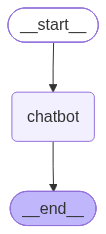

In [8]:
graph

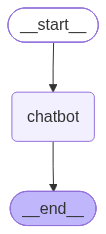

In [9]:
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Error displaying graph:", e)

In [10]:
res = graph.invoke({"messages": "Hi, how are you?"})
res

{'messages': [HumanMessage(content='Hi, how are you?', additional_kwargs={}, response_metadata={}, id='2be580da-65ed-44e5-ac56-6b77f82d2221'),
  AIMessage(content="Hello! I'm doing great, thanks for asking. How can I help you today?", additional_kwargs={'reasoning_content': 'The user says "Hi, how are you?" It\'s a casual greeting. Should respond politely. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 77, 'total_tokens': 127, 'completion_time': 0.104120224, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.003087988, 'prompt_tokens_details': None, 'queue_time': 0.34890348, 'total_time': 0.107208212}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8ea50c0161', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a15d98-39de-7842-89af-52a828df1a3b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens':

In [11]:
res["messages"][-1].content


"Hello! I'm doing great, thanks for asking. How can I help you today?"

In [12]:
for event in graph.stream({"messages" : "How are you?"}):
    for value in event.values():
        print(value)

{'messages': [AIMessage(content="I'm doing great, thank you! How can I assist you today?", additional_kwargs={'reasoning_content': 'The user asks "How are you?" This is a simple greeting. We respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 42, 'prompt_tokens': 75, 'total_tokens': 117, 'completion_time': 0.088189679, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.013269948, 'prompt_tokens_details': None, 'queue_time': 0.400351759, 'total_time': 0.101459627}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c868cf1eaa', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a15d98-3c99-7731-a1ba-8889cc19ef77-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 75, 'output_tokens': 42, 'total_tokens': 117, 'output_token_details': {'reasoning': 19}})]}


In [13]:
from langchain_tavily import TavilySearch

tool = TavilySearch(
    api_key=os.environ.get("TAVILY_API_KEY"), max_results = 2)
tool.invoke("What is the capital of France?")

{'query': 'What is the capital of France?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.worldatlas.com/articles/what-is-the-capital-of-france.html',
   'title': 'What is the Capital of France?',
   'content': 'Paris is the capital city of France. The city has an approximate area of 41 square miles with a population of 2,206,488 people as of 2018. Contrary to popular belief, the name of the city did not come from the Paris in Greek myths. Instead, the name Paris is derived from the city’s initial inhabitants who were part of the Celtic Parisii tribe. Sometimes, the city is called the City of Light for two reasons; it was among the first cities to adopt gas for lighting the streets and its role during [...] As the capital city of France, the city plays host to the national government of France. Even the official residence of the president is in the city at the Élysée Palace while the Prime Minister is housed at the Hôtel Matignon. The S

In [14]:
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the product."""
    return a * b

In [15]:
tools = [multiply, tool]
model_with_tools = model.bind_tools(tools)

In [16]:
model_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.4.6'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x00000231699000B0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023167B4BC20>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'multiply', 'description': 'Multiply two integers and return the product.', 'parameters':

In [23]:
from langgraph.prebuilt import ToolNode, tools_condition

builder1 = StateGraph(State)

def tool_calling(state: State):
    return {"messages": [model_with_tools.invoke(state["messages"])]}

builder1.add_node("tool_calling", tool_calling)
builder1.add_node("tools", ToolNode(tools))

builder1.add_edge(START, "tool_calling")
builder1.add_conditional_edges("tool_calling", tools_condition)   # ← positional
builder1.add_edge("tools", END)                        # ← loop back

graph = builder1.compile()

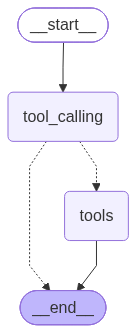

In [24]:
graph

In [25]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [26]:
response["messages"][-1].content

'{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=KGcuuhqmPhI", "title": "AI News: 6 New Models & A Nano Banana Killer", "content": "# AI News: 6 New Models & A Nano Banana Killer\\n## Channel: Matt Wolfe (verified)\\n1.02M subscribers\\n184 likes\\n\\n### Description\\n2,631 views\\nPosted: 2026-10-16\\nGet free credits when you sign up for @GensparkProduct Design here: \\n\\nThis week in AI: Krea 3 makes image editing seriously easy, Google’s Gemini 4 Argon and Meta’s Muse Wonder get put to the test, and new open-weight models keep coming. Plus, the latest OpenAI updates, Grok Voice 3.0, and a rapid-fire roundup of AI news.\\n\\nSharing the latest news and advancements in AI\\n\\nDiscover More:\\n🛠️ Explore AI Tools & News: \\n📰 Weekly Newsletter: \\n\\nSocials:\\n❌ Twiter/X: \\n🖼️ Instagram:   / mr.eflow  \\n🧵 Threads: \\n🟦 LinkedIn:   / matt-wolfe-30841712  \\n👍 Facebook:   / mattrwolfe [...]

In [27]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_39eec2a5-21ca-44f5-9468-b23c6fb9d69d)
 Call ID: fc_39eec2a5-21ca-44f5-9468-b23c6fb9d69d
  Args:
    query: latest AI news
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=KGcuuhqmPhI", "title": "AI News: 6 New Models & A Nano Banana Killer", "content": "# AI News: 6 New Models & A Nano Banana Killer\n## Channel: Matt Wolfe (verified)\n1.02M subscribers\n184 likes\n\n### Description\n2,631 views\nPosted: 2026-10-16\nGet free credits when you sign up for @GensparkProduct Design here: \n\nThis week in AI: Krea 3 makes image editing se

In [28]:
response = graph.invoke({"messages":"Give me recent ai news and multiply 5 with 10?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and multiply 5 with 10?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_900cd884-3fae-49c9-ada3-e785a1b9b240)
 Call ID: fc_900cd884-3fae-49c9-ada3-e785a1b9b240
  Args:
    query: latest AI news 2024 October
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2024 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ipsos.com/en-us/artificial-intelligence-key-insights-data-and-tables", "title": "Artificial Intelligence: Key insights, data and tables | Ipsos", "content": "Why do we worry so much about AI? — March 14, 2025\n There's a negative trend in words we use to describe AI art — March 14, 2025\n Americans still have a complicated relationship w

React Agent Arch

In [29]:
from langgraph.prebuilt import ToolNode, tools_condition

builder1 = StateGraph(State)

def tool_calling(state: State):
    return {"messages": [model_with_tools.invoke(state["messages"])]}

builder1.add_node("tool_calling", tool_calling)
builder1.add_node("tools", ToolNode(tools))

builder1.add_edge(START, "tool_calling")
builder1.add_conditional_edges("tool_calling", tools_condition)   # ← positional
builder1.add_edge("tools", "tool_calling")                        # ← loop back

graph = builder1.compile()

In [30]:
response = graph.invoke({"messages":"Give me recent ai news and multiply 5 with 10?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me recent ai news and multiply 5 with 10?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_beae22c0-381e-4d61-824f-5754283a1064)
 Call ID: fc_beae22c0-381e-4d61-824f-5754283a1064
  Args:
    query: latest AI news 2024 October
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2024 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ipsos.com/en-us/artificial-intelligence-key-insights-data-and-tables", "title": "Artificial Intelligence: Key insights, data and tables | Ipsos", "content": "Why do we worry so much about AI? — March 14, 2025\n There's a negative trend in words we use to describe AI art — March 14, 2025\n Americans still have a complicated relationship w

Adding Memory In Agentic Graph


In [31]:
response=graph.invoke({"messages":"Hello my name is KRish"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is KRish
================================== Ai Message ==================================

Hello, Krish! 👋 Nice to meet you. How can I assist you today?


In [32]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don’t have any information about your name. If you’d like to share it, feel free to let me know!


In [37]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()
def tool_calling_llm(state:State):
    return {"messages":[model_with_tools.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)


In [38]:
config={"configurable":{"thread_id":"1"}}

In [39]:
response=graph.invoke({"messages":"Hi my name is Krish"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='145de414-8e4b-488c-8d12-a58df23967b8'),
  AIMessage(content='Hi Krish! 👋 Nice to meet you. How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Krish". Likely wants a greeting and perhaps to start conversation. We can respond politely, ask how can help.'}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 345, 'total_tokens': 405, 'completion_time': 0.130921422, 'completion_tokens_details': {'reasoning_tokens': 33}, 'prompt_time': 0.019239797, 'prompt_tokens_details': None, 'queue_time': 2.3042370979999998, 'total_time': 0.150161219}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a15db1-2120-75a3-a941-6a960cd5920e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata=

In [40]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

Absolutely—I’ve got your name as **Krish**. 😊 What’s on your mind today?


Streaming


In [60]:
def superbot(state:State):
    return {"messages":[model_with_tools.invoke(state['messages'])]}

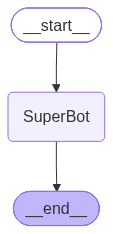

In [64]:
graph_builder = StateGraph(State)
graph_builder.add_node("SuperBot", superbot)
graph_builder.add_edge(START, "SuperBot")
graph_builder.add_edge("SuperBot", END)

graph = graph_builder.compile(checkpointer=memory)   # compile the builder
graph

In [65]:
print(model.model_name)

openai/gpt-oss-120b


In [68]:
config = {"configurable": {"thread_id": "2"}}

response = graph.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================== Ai Message ==================================

Hey Krish! 👋 Great to meet you. 

Cricket’s such an exciting sport—do you have a favorite team or player? Are you more into the fast‑bowling action, the classic Test matches, or the high‑scoring T20s? Let me know what you enjoy most about cricket, and we can chat about recent matches, stats, or anything else you

In [70]:
response = graph.invoke({"messages":"What is my name?"} , config)
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================ Human Message =================================

Hi,My name is Krish And I like cricket
================================== Ai Message ==================================

Hey Krish! 👋 Great to meet you. 

Cricket’s such an exciting sport—do you have a favorite team or player? Are you more into the fast‑bowling action, the classic Test matches, or the high‑scoring T20s? Let me know what you enjoy most about cricket, and we can chat about recent matches, stats, or anything else you

Streaming

Methods: .stream() and astream()

    These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

    values : This streams the full state of the graph after each node is called.
    updates : This streams updates to the state of the graph after each node is called.


In [72]:
config = {"configurable": {"thread_id": "3"}}

for chunk in graph.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Krish! 👋 Nice to meet you.  \n\nCricket’s a fantastic sport—whether you’re into the strategic depth of Test cricket, the fast‑paced excitement of T20s, or the classic drama of ODIs, there’s always something to talk about.\n\nDo you have a favorite team (India, Australia, England, etc.) or a player you admire? Maybe a particular match that stuck with you? I’m all ears and happy to chat about scores, upcoming series, historic moments, or anything cricket‑related you’d like!', additional_kwargs={'reasoning_content': 'The user repeats the same message. Possibly they want a response. They said "Hi, My name is Krish And I like cricket". We responded earlier. Maybe they want something else? Could be they want a conversation about cricket. Should ask follow-up. Provide friendly reply.'}, response_metadata={'token_usage': {'completion_tokens': 178, 'prompt_tokens': 472, 'total_tokens': 650, 'completion_time': 0.366789851, 'completion_tokens_deta

In [75]:
for chunk in graph.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='d3151daf-f2aa-43a9-9786-758e3ca684ea'), HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='51daa691-30dd-49dd-aff1-7e15be9548c9'), AIMessage(content='Hello Krish! 👋 It’s great to meet you. \n\nCricket is such an exciting sport—there’s always something happening, whether it’s a nail‑biting Test match, a high‑scoring ODI, or a fast‑paced T20 thriller. Do you have a favorite team or player you follow? Maybe you’ve got a memorable match you love to talk about? I’d love to hear more!', additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Likely they want a friendly response. Maybe ask about favorite team, etc. No need for tools.'}, response_metadata={'token_usage': {'completion_tokens': 133, 'prompt_tokens': 365, 'total_tokens': 498, 'completion_time': 0.279160757,

In [76]:
for chunk in graph.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='d3151daf-f2aa-43a9-9786-758e3ca684ea'), HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='51daa691-30dd-49dd-aff1-7e15be9548c9'), AIMessage(content='Hello Krish! 👋 It’s great to meet you. \n\nCricket is such an exciting sport—there’s always something happening, whether it’s a nail‑biting Test match, a high‑scoring ODI, or a fast‑paced T20 thriller. Do you have a favorite team or player you follow? Maybe you’ve got a memorable match you love to talk about? I’d love to hear more!', additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Likely they want a friendly response. Maybe ask about favorite team, etc. No need for tools.'}, response_metadata={'token_usage': {'completion_tokens': 133, 'prompt_tokens': 365, 'total_tokens': 498, 'completion_time': 0.279160757,